# Handwritten Digit Recognition Using Deep Learning
# Comparative Analysis of Multiple Models

---

**B.Tech Computer Science - Deep Learning Project**

This notebook compares different models for recognizing handwritten digits (0-9). We will train 4 models, compare them, and save the best one.

**Note:** This notebook is only for training and comparison. The GUI will be built separately.

---

## Section 1: Project Introduction

### What is this project about?

We want to build a system that can look at a picture of a handwritten digit (like 0, 1, 2... up to 9) and correctly tell which digit it is. This is called **Handwritten Digit Recognition**.

Instead of just building one model, we build **four different models** and compare them to find which one works best. This is called **Comparative Analysis**.

### Why is this useful?

- Used in post offices to read pin codes on letters
- Used in banks to read cheque amounts
- Used to convert handwritten forms into digital text
- Helps us understand which type of model works best for image tasks

### What are we comparing?

| # | Model | Type |
|---|-------|------|
| 1 | ANN (Artificial Neural Network) | Deep Learning |
| 2 | Basic CNN (Convolutional Neural Network) | Deep Learning |
| 3 | Enhanced CNN (with extra techniques) | Deep Learning |
| 4 | SVM (Support Vector Machine) | Traditional Machine Learning |

### What will we measure?

- **Accuracy** - How many digits it gets right
- **F1-Score** - A balanced score considering all classes
- **Training Time** - How long it takes to train
- **Speed** - How fast it can predict a digit
- **Size** - How big the saved model file is

### What we will NOT do in this notebook

- No GUI or app building (that comes later)
- No data augmentation or transfer learning
- No overly complex architectures

---
## Section 2: Import Libraries and Setup

In [2]:
# ========================
# Import everything we need
# ========================

import os
import json
import time
import random
import shutil
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks

from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
from sklearn.model_selection import train_test_split
import joblib

warnings.filterwarnings('ignore')

# Set random seed so results are reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Print versions
print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

import sklearn
print("Scikit-learn version:", sklearn.__version__)

# Set up plotting style
plt.rcParams['figure.figsize'] = (10, 6)
sns.set_style('whitegrid')


TensorFlow version: 2.21.0
NumPy version: 2.1.3
Scikit-learn version: 1.6.1


---
## Section 3: Load and Explore the Dataset

We use the **MNIST dataset** which is a famous dataset of handwritten digits.
- It has **70,000 images** total
- Each image is **28x28 pixels** and **grayscale** (black and white)
- There are **10 classes**: digits 0 through 9
- It comes pre-split: 60,000 for training and 10,000 for testing

In [3]:
# Load MNIST dataset
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Dataset loaded!")
print(f"Training images: {x_train_full.shape[0]}")
print(f"Test images: {x_test.shape[0]}")
print(f"Image size: {x_train_full.shape[1]}x{x_train_full.shape[2]} pixels")
print(f"Pixel value range: {x_train_full.min()} to {x_train_full.max()}")
print(f"Labels: {np.unique(y_train_full)}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset loaded!
Training images: 60000
Test images: 10000
Image size: 28x28 pixels
Pixel value range: 0 to 255
Labels: [0 1 2 3 4 5 6 7 8 9]


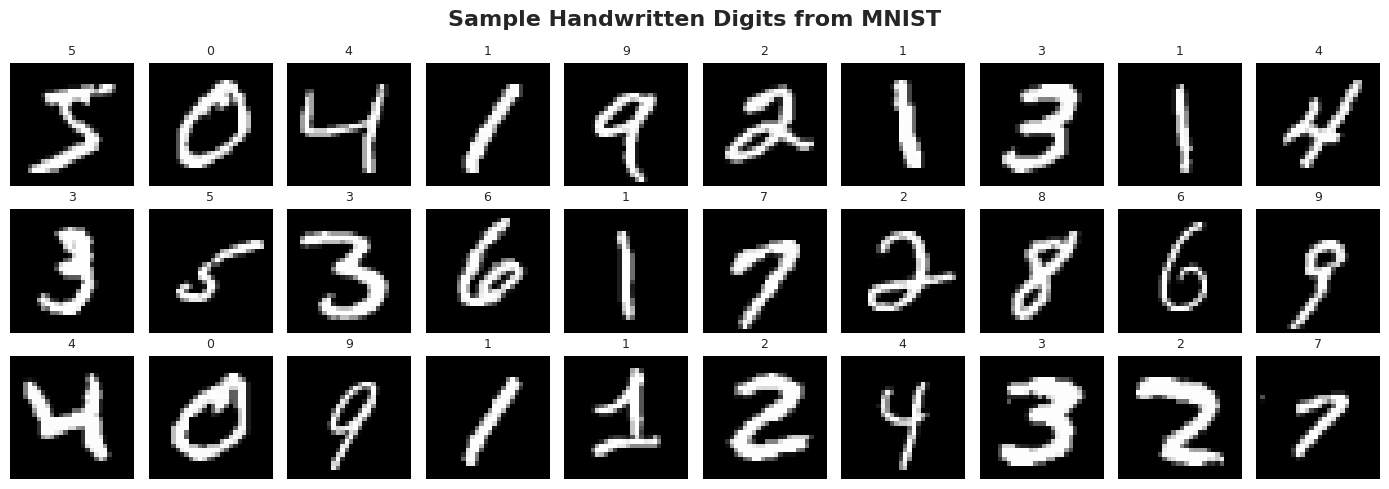

In [4]:
# Show some sample images
fig, axes = plt.subplots(3, 10, figsize=(14, 5))
fig.suptitle('Sample Handwritten Digits from MNIST', fontsize=16, fontweight='bold')

for i in range(30):
    row = i // 10
    col = i % 10
    axes[row][col].imshow(x_train_full[i], cmap='gray')
    axes[row][col].set_title(f'{y_train_full[i]}', fontsize=9)
    axes[row][col].axis('off')

plt.tight_layout()
plt.savefig('artifacts/sample_digits.png')
plt.show()

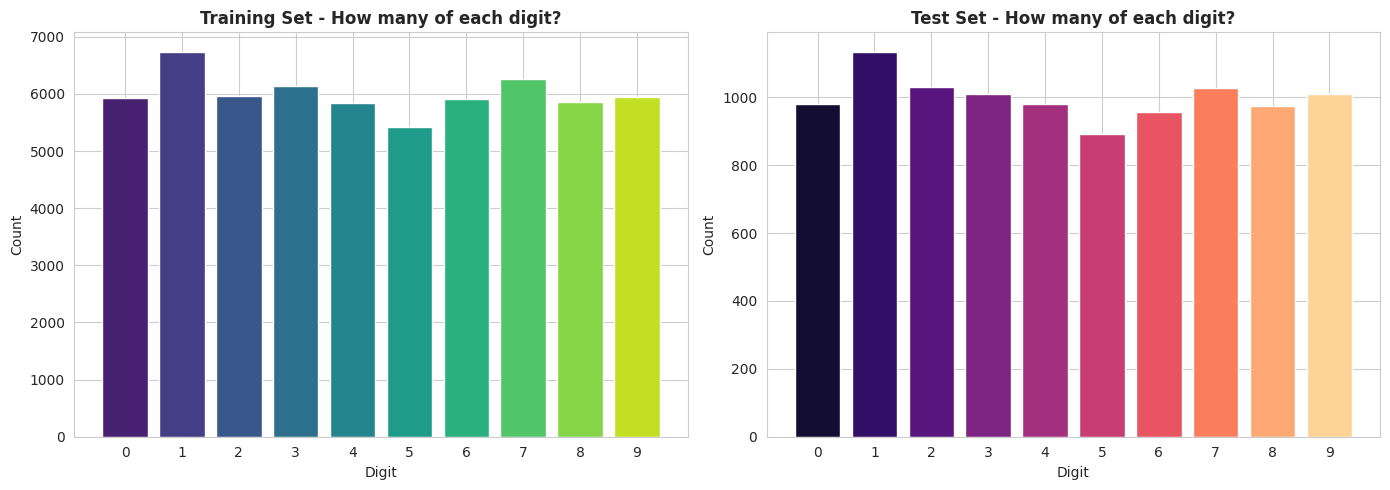

The dataset is roughly balanced - each digit appears about the same number of times.


In [5]:
# How many images of each digit?
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Training set distribution
digits, counts = np.unique(y_train_full, return_counts=True)
axes[0].bar(digits, counts, color=sns.color_palette('viridis', 10))
axes[0].set_title('Training Set - How many of each digit?', fontweight='bold')
axes[0].set_xlabel('Digit')
axes[0].set_ylabel('Count')
axes[0].set_xticks(range(10))

# Test set distribution
digits_t, counts_t = np.unique(y_test, return_counts=True)
axes[1].bar(digits_t, counts_t, color=sns.color_palette('magma', 10))
axes[1].set_title('Test Set - How many of each digit?', fontweight='bold')
axes[1].set_xlabel('Digit')
axes[1].set_ylabel('Count')
axes[1].set_xticks(range(10))

plt.tight_layout()
plt.savefig('artifacts/digit_distribution.png')
plt.show()

print("The dataset is roughly balanced - each digit appears about the same number of times.")

---
## Section 4: Prepare the Data

Before training, we need to prepare the data:

1. **Normalize**: Pixel values go from 0-255. We divide by 255 to make them 0-1. This helps the models learn faster.

2. **Split**: We split the 60,000 training images into:
   - 54,000 for actual training
   - 6,000 for validation (to check if the model is learning well)
   - The 10,000 test images stay separate and are ONLY used at the end.

3. **Reshape**: CNNs need images in shape (28, 28, 1) with a channel dimension. ANN and SVM need flat vectors of 784 numbers.

In [6]:
NUM_CLASSES = 10

# Step 1: Normalize pixel values to 0-1
x_train_full_norm = x_train_full.astype('float32') / 255.0
x_test_norm = x_test.astype('float32') / 255.0

# Step 2: Split into training (90%) and validation (10%)
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full_norm, y_train_full,
    test_size=0.1,
    random_state=SEED,
    stratify=y_train_full  # keep same proportion of each digit
)

# Step 3a: Reshape for CNN models - add channel dimension
x_train_cnn = x_train[..., np.newaxis]  # shape: (54000, 28, 28, 1)
x_val_cnn = x_val[..., np.newaxis]      # shape: (6000, 28, 28, 1)
x_test_cnn = x_test_norm[..., np.newaxis] # shape: (10000, 28, 28, 1)

# Step 3b: Flatten for ANN and SVM models
x_train_flat = x_train.reshape(-1, 784)  # shape: (54000, 784)
x_val_flat = x_val.reshape(-1, 784)      # shape: (6000, 784)
x_test_flat = x_test_norm.reshape(-1, 784) # shape: (10000, 784)

# Print final shapes
print("Data shapes after preprocessing:")
print(f"  Training:   CNN={x_train_cnn.shape}, Flat={x_train_flat.shape}, Labels={y_train.shape}")
print(f"  Validation: CNN={x_val_cnn.shape}, Flat={x_val_flat.shape}, Labels={y_val.shape}")
print(f"  Test:       CNN={x_test_cnn.shape}, Flat={x_test_flat.shape}, Labels={y_test.shape}")
print(f"\nPixel range: {x_train.min()} to {x_train.max()}")

Data shapes after preprocessing:
  Training:   CNN=(54000, 28, 28, 1), Flat=(54000, 784), Labels=(54000,)
  Validation: CNN=(6000, 28, 28, 1), Flat=(6000, 784), Labels=(6000,)
  Test:       CNN=(10000, 28, 28, 1), Flat=(10000, 784), Labels=(10000,)

Pixel range: 0.0 to 1.0


---
## Helper Functions

We create a few simple helper functions that we'll reuse for every model. This avoids writing the same code 4 times.

In [7]:
# Dictionary to store results for all models
all_results = {}


def plot_history(history, name):
    """Plot the training and validation accuracy and loss curves."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Accuracy plot
    ax1.plot(history.history['accuracy'], label='Train')
    ax1.plot(history.history['val_accuracy'], label='Validation')
    ax1.set_title(f'{name} - Accuracy')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend()

    # Loss plot
    ax2.plot(history.history['loss'], label='Train')
    ax2.plot(history.history['val_loss'], label='Validation')
    ax2.set_title(f'{name} - Loss')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend()

    plt.tight_layout()
    safe = name.replace(' ', '_').lower()
    plt.savefig(f'artifacts/{safe}_curves.png')
    plt.show()


def plot_confusion(y_true, y_pred, name, color='Blues'):
    """Plot a confusion matrix."""
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap=color,
                xticklabels=range(10), yticklabels=range(10))
    plt.title(f'{name} - Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    safe = name.replace(' ', '_').lower()
    plt.savefig(f'artifacts/{safe}_cm.png')
    plt.show()


def print_metrics(name, y_true, y_pred):
    """Calculate and print all metrics for a model."""
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro')
    rec = recall_score(y_true, y_pred, average='macro')
    f1_mac = f1_score(y_true, y_pred, average='macro')
    f1_wt = f1_score(y_true, y_pred, average='weighted')

    print(f"\n--- {name} Results ---")
    print(f"  Accuracy:         {acc*100:.2f}%")
    print(f"  Macro Precision:  {prec*100:.2f}%")
    print(f"  Macro Recall:     {rec*100:.2f}%")
    print(f"  Macro F1-Score:   {f1_mac*100:.2f}%")
    print(f"  Weighted F1:      {f1_wt*100:.2f}%")

    print(f"\nClassification Report:")
    print(classification_report(y_true, y_pred))

    return acc, prec, rec, f1_mac, f1_wt

---
## Section 5: Model 1 - ANN (Artificial Neural Network)

An ANN is the simplest type of neural network. It has layers of neurons where **every neuron connects to every neuron in the next layer** (that's why they're called "fully connected" or "Dense" layers).

**How it works for images:**
- We flatten the 28x28 image into a long list of 784 numbers
- The network tries to learn patterns from these numbers

**Weakness:** It treats every pixel as independent - it doesn't understand that nearby pixels are related (it ignores the image structure).

**Our architecture:**
- Input: 784 numbers
- Hidden Layer 1: 512 neurons with ReLU
- Hidden Layer 2: 256 neurons with ReLU
- Hidden Layer 3: 128 neurons with ReLU
- Output: 10 neurons with Softmax (one for each digit)

In [8]:
# Build the ANN model
ann_model = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(512, activation='relu'),
    layers.Dense(256, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
], name='ANN')

ann_model.summary()

Model: "ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 567,434 (2.16 MB)

 Trainable params: 567,434 (2.16 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Compile and train
ann_model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

print("Training ANN...\n")
ann_start = time.time()
ann_history = ann_model.fit(x_train_flat, y_train,
                           epochs=15, batch_size=128,
                           validation_data=(x_val_flat, y_val))
ann_train_time = time.time() - ann_start
print(f"\nDone! Training took {ann_train_time:.1f} seconds")

Training ANN...

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9293 - loss: 0.2386 - val_accuracy: 0.9615 - val_loss: 0.1313
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9730 - loss: 0.0872 - val_accuracy: 0.9668 - val_loss: 0.1112
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9835 - loss: 0.0529 - val_accuracy: 0.9725 - val_loss: 0.1055
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9871 - loss: 0.0391 - val_accuracy: 0.9737 - val_loss: 0.1022
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9886 - loss: 0.0343 - val_accuracy: 0.9768 - val_loss: 0.0973
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9916 - loss: 0.0256 - val_accuracy: 0.9757 - val_loss: 0.1082
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9922 - loss: 0.0223 - val_accuracy: 0.9728 - val_loss: 0.1210
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9944 - loss: 0.0169 

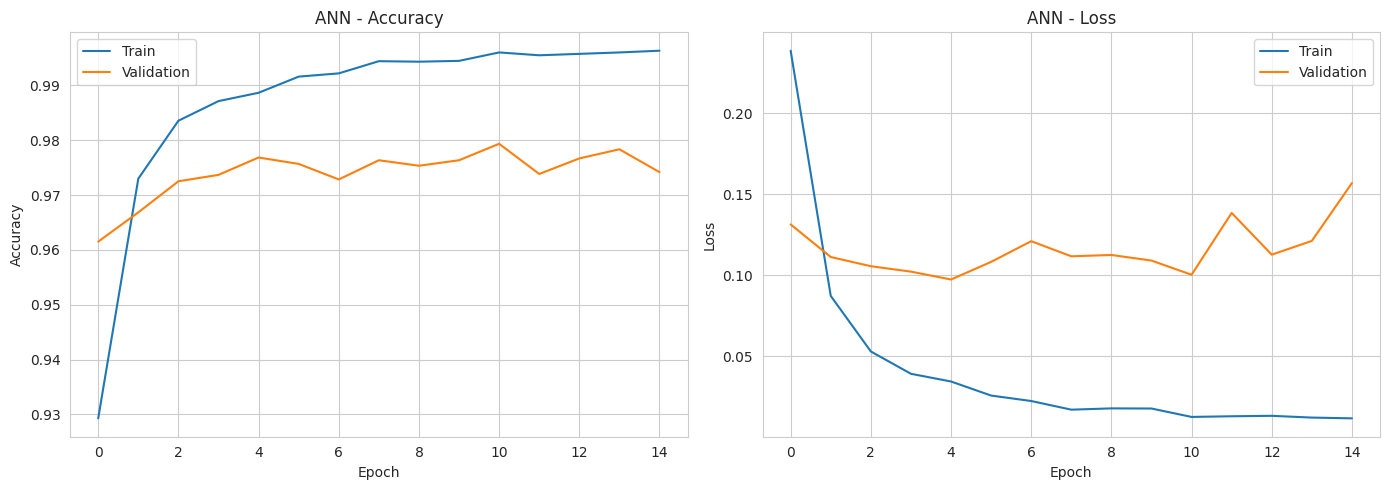

In [10]:
# Plot training curves
plot_history(ann_history, 'ANN')


--- ANN Results ---
  Accuracy:         97.70%
  Macro Precision:  97.71%
  Macro Recall:     97.70%
  Macro F1-Score:   97.69%
  Weighted F1:      97.71%

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.98      0.98      1032
           3       0.99      0.97      0.98      1010
           4       0.99      0.96      0.98       982
           5       0.97      0.98      0.98       892
           6       0.98      0.98      0.98       958
           7       0.99      0.97      0.98      1028
           8       0.93      0.99      0.96       974
           9       0.96      0.96      0.96      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



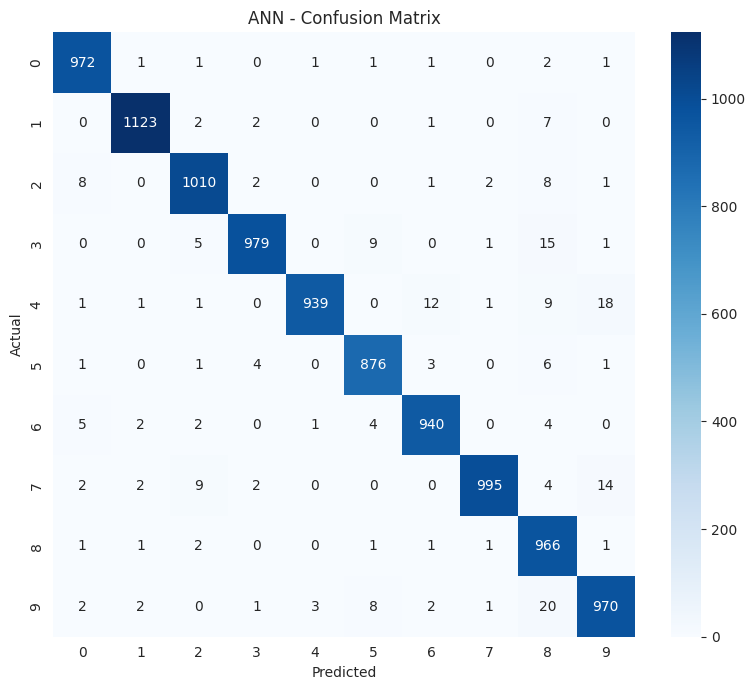


Model saved! Size: 6.52 MB
Inference time: 1.7494s for 10000 images


In [11]:
# Test the ANN
_ = ann_model.predict(x_test_flat[:10], verbose=0)  # warm up

ann_inf_start = time.time()
ann_probs = ann_model.predict(x_test_flat, verbose=0)
ann_inf_time = time.time() - ann_inf_start

ann_preds = np.argmax(ann_probs, axis=1)
ann_acc, ann_prec, ann_rec, ann_f1, ann_f1w = print_metrics('ANN', y_test, ann_preds)

# Confusion matrix
plot_confusion(y_test, ann_preds, 'ANN', 'Blues')

# Save model
ann_model.save('artifacts/ann_model.keras')
ann_size = os.path.getsize('artifacts/ann_model.keras') / (1024*1024)
ann_val_acc = max(ann_history.history['val_accuracy'])

# Store results
all_results['ANN'] = {
    'val_accuracy': ann_val_acc,
    'test_accuracy': ann_acc,
    'precision': ann_prec,
    'recall': ann_rec,
    'f1_macro': ann_f1,
    'f1_weighted': ann_f1w,
    'train_time': round(ann_train_time, 2),
    'inference_time': round(ann_inf_time, 4),
    'latency_ms': round(ann_inf_time / len(y_test) * 1000, 4),
    'params': ann_model.count_params(),
    'size_mb': round(ann_size, 3),
    'path': 'artifacts/ann_model.keras',
    'type': 'keras',
    'preds': ann_preds,
    'probs': ann_probs
}

print(f"\nModel saved! Size: {ann_size:.2f} MB")
print(f"Inference time: {ann_inf_time:.4f}s for {len(y_test)} images")

---
## Section 6: Model 2 - Basic CNN (Convolutional Neural Network)

A CNN is designed specifically for images. Instead of treating every pixel independently, it uses **filters** (small windows) that slide across the image to detect patterns.

**How it works:**
- **Convolutional layers** use small filters (e.g., 3x3) that scan the image and detect features like edges, curves, and shapes
- **Pooling layers** shrink the image to keep only the important parts
- **Dense layers** at the end make the final decision

Think of it like this: First layers detect simple edges, deeper layers combine edges into shapes, and final layers recognize which digit those shapes form.

**Our architecture:**
- Conv2D (32 filters, 3x3) + ReLU + MaxPool (2x2)
- Conv2D (64 filters, 3x3) + ReLU + MaxPool (2x2)
- Flatten + Dense (128, ReLU) + Dense (10, Softmax)

In [12]:
# Build the Basic CNN model
basic_cnn = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
], name='Basic_CNN')

basic_cnn.summary()

Model: "Basic_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Compile and train
basic_cnn.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

print("Training Basic CNN...\n")
cnn_start = time.time()
cnn_history = basic_cnn.fit(x_train_cnn, y_train,
                           epochs=15, batch_size=128,
                           validation_data=(x_val_cnn, y_val))
cnn_train_time = time.time() - cnn_start
print(f"\nDone! Training took {cnn_train_time:.1f} seconds")

Training Basic CNN...

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.9329 - loss: 0.2280 - val_accuracy: 0.9728 - val_loss: 0.0948
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9808 - loss: 0.0621 - val_accuracy: 0.9785 - val_loss: 0.0797
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9872 - loss: 0.0423 - val_accuracy: 0.9847 - val_loss: 0.0566
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9907 - loss: 0.0309 - val_accuracy: 0.9870 - val_loss: 0.0532
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9929 - loss: 0.0236 - val_accuracy: 0.9865 - val_loss: 0.0567
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9945 - loss: 0.0184 - val_accuracy: 0.9865 - val_loss: 0.0597
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9955 - loss: 0.0151 - val_accuracy: 0.9845 - val_loss: 0.0618
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9959 - loss: 

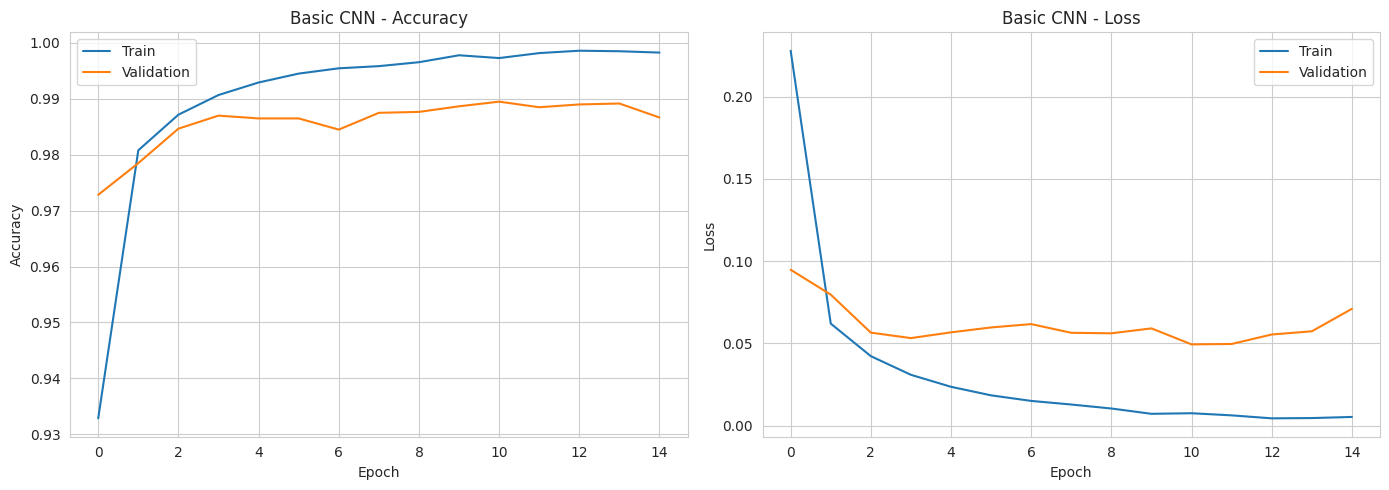

In [14]:
plot_history(cnn_history, 'Basic CNN')


--- Basic CNN Results ---
  Accuracy:         98.98%
  Macro Precision:  98.97%
  Macro Recall:     98.97%
  Macro F1-Score:   98.97%
  Weighted F1:      98.98%

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       1.00      0.99      1.00      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.98      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.98      0.99      0.98       892
           6       0.98      1.00      0.99       958
           7       0.98      1.00      0.99      1028
           8       0.99      0.98      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



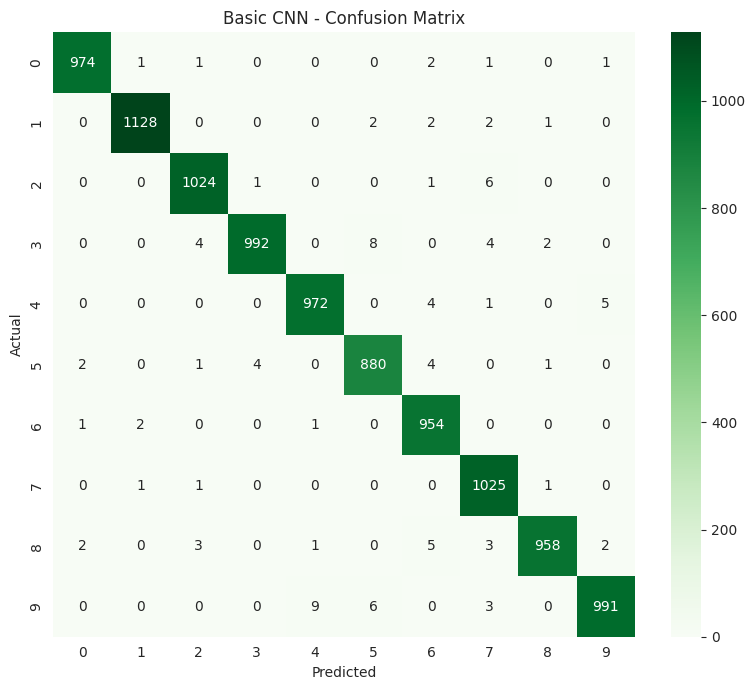


Model saved! Size: 2.61 MB


In [15]:
# Test the Basic CNN
_ = basic_cnn.predict(x_test_cnn[:10], verbose=0)  # warm up

cnn_inf_start = time.time()
cnn_probs = basic_cnn.predict(x_test_cnn, verbose=0)
cnn_inf_time = time.time() - cnn_inf_start

cnn_preds = np.argmax(cnn_probs, axis=1)
cnn_acc, cnn_prec, cnn_rec, cnn_f1, cnn_f1w = print_metrics('Basic CNN', y_test, cnn_preds)

plot_confusion(y_test, cnn_preds, 'Basic CNN', 'Greens')

# Save model
basic_cnn.save('artifacts/basic_cnn_model.keras')
cnn_size = os.path.getsize('artifacts/basic_cnn_model.keras') / (1024*1024)
cnn_val_acc = max(cnn_history.history['val_accuracy'])

all_results['Basic CNN'] = {
    'val_accuracy': cnn_val_acc,
    'test_accuracy': cnn_acc,
    'precision': cnn_prec,
    'recall': cnn_rec,
    'f1_macro': cnn_f1,
    'f1_weighted': cnn_f1w,
    'train_time': round(cnn_train_time, 2),
    'inference_time': round(cnn_inf_time, 4),
    'latency_ms': round(cnn_inf_time / len(y_test) * 1000, 4),
    'params': basic_cnn.count_params(),
    'size_mb': round(cnn_size, 3),
    'path': 'artifacts/basic_cnn_model.keras',
    'type': 'keras',
    'preds': cnn_preds,
    'probs': cnn_probs
}

print(f"\nModel saved! Size: {cnn_size:.2f} MB")

---
## Section 7: Model 3 - Enhanced CNN

This is a better version of the Basic CNN. We add some extra techniques to help it learn better and avoid overfitting:

- **More Conv layers:** More layers = can detect more complex patterns
- **Batch Normalization:** Keeps the numbers flowing through the network in a nice range, which makes training faster and more stable
- **Dropout:** Randomly turns off some neurons during training. This forces the network to not rely too heavily on any single neuron, making it more robust
- **Early Stopping:** Automatically stops training if the model stops improving

**Our architecture:**
- Block 1: Conv(32) + BatchNorm + ReLU + Conv(32) + BatchNorm + ReLU + MaxPool + Dropout(25%)
- Block 2: Conv(64) + BatchNorm + ReLU + Conv(64) + BatchNorm + ReLU + MaxPool + Dropout(25%)
- Flatten + Dense(256) + BatchNorm + ReLU + Dropout(50%) + Output(10)

In [16]:
# Build the Enhanced CNN model
enhanced_cnn = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Block 1
    layers.Conv2D(32, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(32, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Block 2
    layers.Conv2D(64, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(64, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Classification part
    layers.Flatten(),
    layers.Dense(256),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
], name='Enhanced_CNN')

enhanced_cnn.summary()

Model: "Enhanced_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       803,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 872,426 (3.33 MB)

 Trainable params: 871,530 (3.32 MB)

 Non-trainable params: 896 (3.50 KB)

In [17]:
# Compile and train with early stopping
enhanced_cnn.compile(optimizer='adam',
                     loss='sparse_categorical_crossentropy',
                     metrics=['accuracy'])

# Stop early if validation loss doesn't improve for 5 epochs
early_stop = callbacks.EarlyStopping(
    monitor='val_loss', patience=5,
    restore_best_weights=True, verbose=1
)

print("Training Enhanced CNN (up to 20 epochs, may stop early)...\n")
ecnn_start = time.time()
ecnn_history = enhanced_cnn.fit(x_train_cnn, y_train,
                               epochs=20, batch_size=128,
                               validation_data=(x_val_cnn, y_val),
                               callbacks=[early_stop])
ecnn_train_time = time.time() - ecnn_start
print(f"\nDone! Training took {ecnn_train_time:.1f} seconds")

Training Enhanced CNN (up to 20 epochs, may stop early)...

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 29s 40ms/step - accuracy: 0.9481 - loss: 0.1697 - val_accuracy: 0.9190 - val_loss: 0.2564
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9809 - loss: 0.0635 - val_accuracy: 0.9870 - val_loss: 0.0481
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9848 - loss: 0.0491 - val_accuracy: 0.9883 - val_loss: 0.0423
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9879 - loss: 0.0395 - val_accuracy: 0.9907 - val_loss: 0.0319
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9895 - loss: 0.0338 - val_accuracy: 0.9882 - val_loss: 0.0345
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9910 - loss: 0.0299 - val_accuracy: 0.9887 - val_loss: 0.0371
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9919 - loss: 0.0265 - val_accuracy: 0.9917 - val_loss: 0.0286
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━

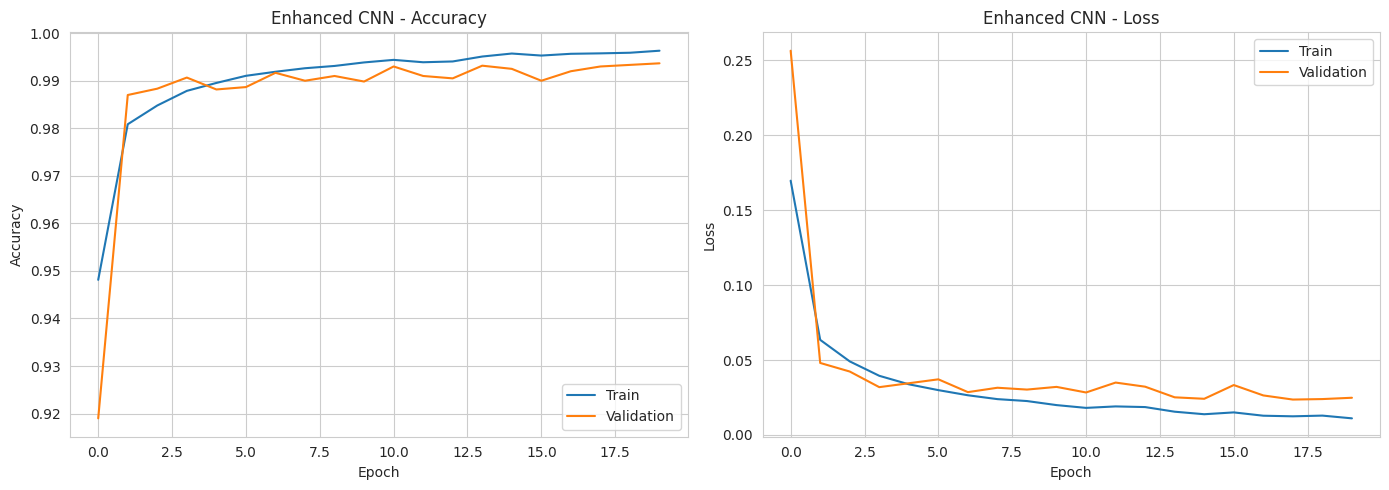

In [18]:
plot_history(ecnn_history, 'Enhanced CNN')


--- Enhanced CNN Results ---
  Accuracy:         99.40%
  Macro Precision:  99.39%
  Macro Recall:     99.39%
  Macro F1-Score:   99.39%
  Weighted F1:      99.40%

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       980
           1       1.00      1.00      1.00      1135
           2       1.00      0.99      1.00      1032
           3       0.99      1.00      0.99      1010
           4       1.00      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       1.00      0.99      0.99       958
           7       0.99      1.00      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



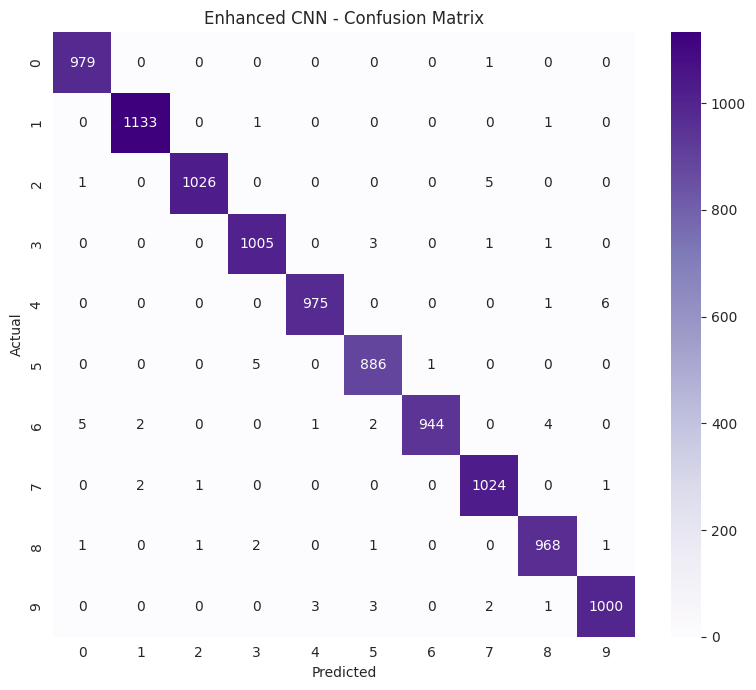


Model saved! Size: 10.07 MB


In [19]:
# Test the Enhanced CNN
_ = enhanced_cnn.predict(x_test_cnn[:10], verbose=0)  # warm up

ecnn_inf_start = time.time()
ecnn_probs = enhanced_cnn.predict(x_test_cnn, verbose=0)
ecnn_inf_time = time.time() - ecnn_inf_start

ecnn_preds = np.argmax(ecnn_probs, axis=1)
ecnn_acc, ecnn_prec, ecnn_rec, ecnn_f1, ecnn_f1w = print_metrics('Enhanced CNN', y_test, ecnn_preds)

plot_confusion(y_test, ecnn_preds, 'Enhanced CNN', 'Purples')

# Save model
enhanced_cnn.save('artifacts/enhanced_cnn_model.keras')
ecnn_size = os.path.getsize('artifacts/enhanced_cnn_model.keras') / (1024*1024)
ecnn_val_acc = max(ecnn_history.history['val_accuracy'])

all_results['Enhanced CNN'] = {
    'val_accuracy': ecnn_val_acc,
    'test_accuracy': ecnn_acc,
    'precision': ecnn_prec,
    'recall': ecnn_rec,
    'f1_macro': ecnn_f1,
    'f1_weighted': ecnn_f1w,
    'train_time': round(ecnn_train_time, 2),
    'inference_time': round(ecnn_inf_time, 4),
    'latency_ms': round(ecnn_inf_time / len(y_test) * 1000, 4),
    'params': enhanced_cnn.count_params(),
    'size_mb': round(ecnn_size, 3),
    'path': 'artifacts/enhanced_cnn_model.keras',
    'type': 'keras',
    'preds': ecnn_preds,
    'probs': ecnn_probs
}

print(f"\nModel saved! Size: {ecnn_size:.2f} MB")

### Quick comparison: Basic CNN vs Enhanced CNN

The Enhanced CNN adds Batch Normalization and Dropout. These help the model:
- **Not overfit** (memorize training data too much)
- **Train more stably** (less random jumps in accuracy)

Whether this actually gives better accuracy depends on the results above.

---
## Section 8: Model 4 - SVM (Support Vector Machine)

SVM is **not** a deep learning model. It's a traditional machine learning algorithm. We include it as a **baseline** to compare against our neural networks.

**How SVM works (simple explanation):**
- SVM tries to draw the best possible boundary lines between different classes
- With the RBF kernel, it can draw curved (not just straight) boundaries
- It doesn't learn features like CNNs - it works directly on the raw pixel values

**Important note:** SVM is slow on large datasets. Training on 54,000 images may take several minutes. This is normal.

**Settings used:**
- Kernel: RBF
- C: 10 (controls how strict the boundary is)
- gamma: 'scale' (automatically calculated)

In [20]:
# Train the SVM
print("Training SVM... (this may take a few minutes)\n")

svm_model = SVC(kernel='rbf', C=10, gamma='scale', random_state=SEED)

svm_start = time.time()
svm_model.fit(x_train_flat, y_train)
svm_train_time = time.time() - svm_start

print(f"Done! Training took {svm_train_time:.1f} seconds")

Training SVM... (this may take a few minutes)

Done! Training took 158.4 seconds



--- SVM (RBF) Results ---
  Accuracy:         98.31%
  Macro Precision:  98.31%
  Macro Recall:     98.30%
  Macro F1-Score:   98.30%
  Weighted F1:      98.31%

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.98      0.98      0.98      1032
           3       0.98      0.99      0.99      1010
           4       0.98      0.98      0.98       982
           5       0.99      0.98      0.98       892
           6       0.99      0.99      0.99       958
           7       0.98      0.97      0.98      1028
           8       0.99      0.98      0.98       974
           9       0.97      0.97      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



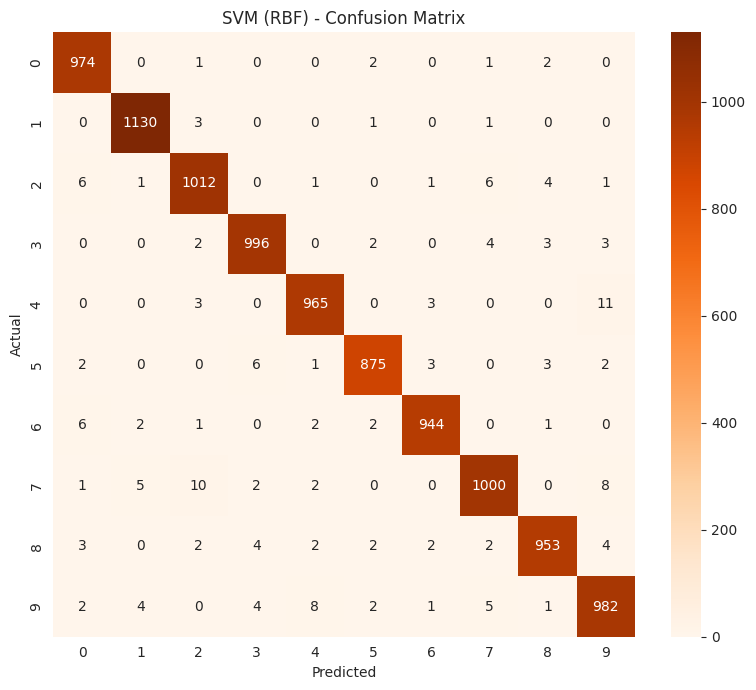


Model saved! Size: 67.08 MB
Inference time: 91.6834s for 10000 images


In [21]:
# Test the SVM
svm_inf_start = time.time()
svm_preds = svm_model.predict(x_test_flat)
svm_inf_time = time.time() - svm_inf_start

svm_acc, svm_prec, svm_rec, svm_f1, svm_f1w = print_metrics('SVM (RBF)', y_test, svm_preds)

plot_confusion(y_test, svm_preds, 'SVM (RBF)', 'Oranges')

# Save model
joblib.dump(svm_model, 'artifacts/svm_model.joblib')
svm_size = os.path.getsize('artifacts/svm_model.joblib') / (1024*1024)

all_results['SVM (RBF)'] = {
    'val_accuracy': np.nan,  # SVM doesn't have validation during training
    'test_accuracy': svm_acc,
    'precision': svm_prec,
    'recall': svm_rec,
    'f1_macro': svm_f1,
    'f1_weighted': svm_f1w,
    'train_time': round(svm_train_time, 2),
    'inference_time': round(svm_inf_time, 4),
    'latency_ms': round(svm_inf_time / len(y_test) * 1000, 4),
    'params': 'N/A',
    'size_mb': round(svm_size, 3),
    'path': 'artifacts/svm_model.joblib',
    'type': 'sklearn',
    'preds': svm_preds,
    'probs': None
}

print(f"\nModel saved! Size: {svm_size:.2f} MB")
print(f"Inference time: {svm_inf_time:.4f}s for {len(y_test)} images")

---
## Section 9: Compare All Models

Now let's put all the results in one table to compare easily.

**Reminder of what we measured:**
- All models used the **same** training, validation, and test data
- **Accuracy** = % of correct predictions
- **Macro F1** = average F1-score across all 10 digits (treats each digit equally)
- **Training time** = how long it took to train
- **Latency** = how fast it predicts one image
- **Params** = number of learnable values (N/A for SVM)
- Neural network inference times include a warm-up run to exclude startup overhead

In [22]:
# Build comparison table
rows = []
for name, r in all_results.items():
    rows.append({
        'Model': name,
        'Val Acc (%)': round(r['val_accuracy'] * 100, 2) if not np.isnan(r['val_accuracy']) else 'N/A',
        'Test Acc (%)': round(r['test_accuracy'] * 100, 2),
        'Macro F1 (%)': round(r['f1_macro'] * 100, 2),
        'Precision (%)': round(r['precision'] * 100, 2),
        'Recall (%)': round(r['recall'] * 100, 2),
        'Train Time (s)': r['train_time'],
        'Latency (ms/img)': r['latency_ms'],
        'Params': f"{r['params']:,}" if r['params'] != 'N/A' else 'N/A',
        'Size (MB)': r['size_mb']
    })

comparison_df = pd.DataFrame(rows)
comparison_df = comparison_df.sort_values('Test Acc (%)', ascending=False)

print("\n" + "="*70)
print("  ALL MODELS - COMPARISON TABLE")
print("="*70)
print(comparison_df.to_string(index=False))

# Save to CSV
comparison_df.to_csv('artifacts/comparison_results.csv', index=False)
print("\nSaved to artifacts/comparison_results.csv")


  ALL MODELS - COMPARISON TABLE
       Model Val Acc (%)  Test Acc (%)  Macro F1 (%)  Precision (%)  Recall (%)  Train Time (s)  Latency (ms/img)  Params  Size (MB)
Enhanced CNN       99.37         99.40         99.39          99.39       99.39          137.34            0.3375 872,426     10.068
   Basic CNN       98.95         98.98         98.97          98.97       98.97           49.51            0.3978 225,034      2.611
   SVM (RBF)         N/A         98.31         98.30          98.31       98.30          158.37            9.1683     N/A     67.076
         ANN       97.93         97.70         97.69          97.71       97.70           34.66            0.1749 567,434      6.523

Saved to artifacts/comparison_results.csv


---
## Section 10: Visualize the Comparison

Let's make charts to see the differences more clearly.

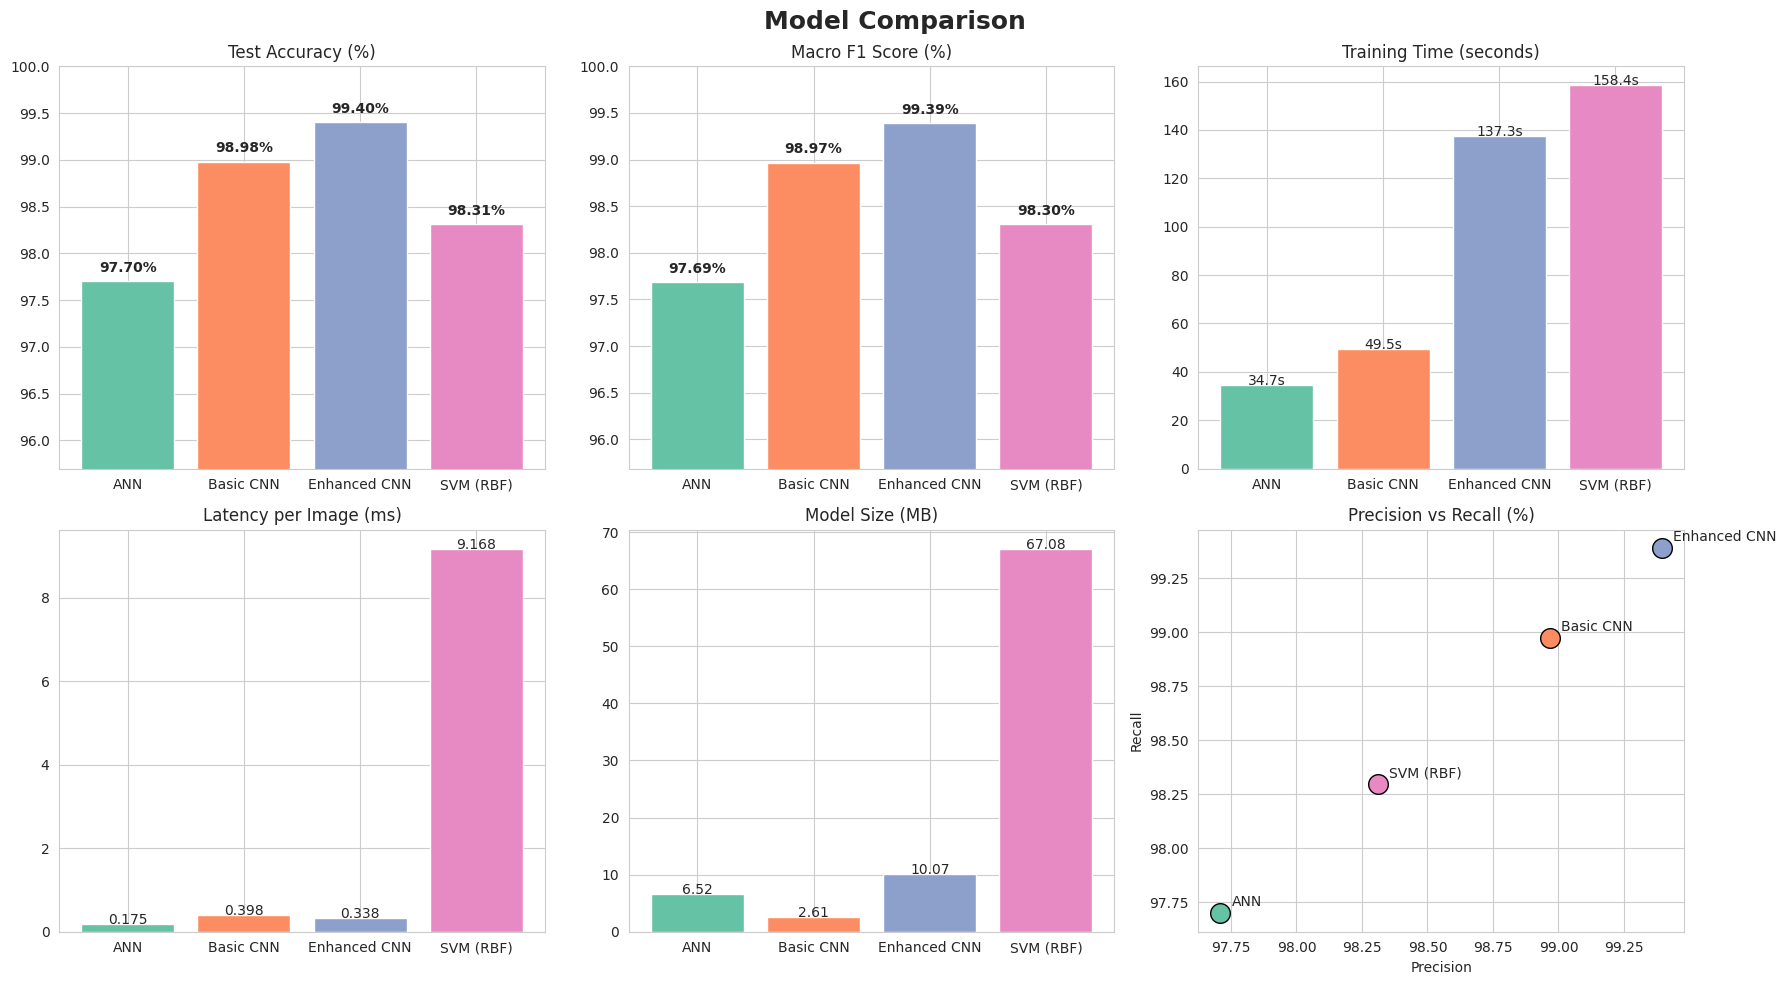

In [23]:
# Get model names and colors
names = list(all_results.keys())
colors = ['#66c2a5', '#fc8d62', '#8da0cb', '#e78ac3']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Model Comparison', fontsize=18, fontweight='bold')

# 1. Test Accuracy
accs = [all_results[n]['test_accuracy'] * 100 for n in names]
bars = axes[0][0].bar(names, accs, color=colors)
axes[0][0].set_title('Test Accuracy (%)')
axes[0][0].set_ylim(min(accs) - 2, 100)
for bar, v in zip(bars, accs):
    axes[0][0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                    f'{v:.2f}%', ha='center', fontweight='bold')

# 2. Macro F1 Score
f1s = [all_results[n]['f1_macro'] * 100 for n in names]
bars = axes[0][1].bar(names, f1s, color=colors)
axes[0][1].set_title('Macro F1 Score (%)')
axes[0][1].set_ylim(min(f1s) - 2, 100)
for bar, v in zip(bars, f1s):
    axes[0][1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                    f'{v:.2f}%', ha='center', fontweight='bold')

# 3. Training Time
times = [all_results[n]['train_time'] for n in names]
bars = axes[0][2].bar(names, times, color=colors)
axes[0][2].set_title('Training Time (seconds)')
for bar, v in zip(bars, times):
    axes[0][2].text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                    f'{v:.1f}s', ha='center')

# 4. Inference Latency
lats = [all_results[n]['latency_ms'] for n in names]
bars = axes[1][0].bar(names, lats, color=colors)
axes[1][0].set_title('Latency per Image (ms)')
for bar, v in zip(bars, lats):
    axes[1][0].text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                    f'{v:.3f}', ha='center')

# 5. Model Size
sizes = [all_results[n]['size_mb'] for n in names]
bars = axes[1][1].bar(names, sizes, color=colors)
axes[1][1].set_title('Model Size (MB)')
for bar, v in zip(bars, sizes):
    axes[1][1].text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                    f'{v:.2f}', ha='center')

# 6. Precision vs Recall scatter
for i, n in enumerate(names):
    axes[1][2].scatter(all_results[n]['precision']*100, all_results[n]['recall']*100,
                       s=200, color=colors[i], edgecolors='black', zorder=5)
    axes[1][2].annotate(n, (all_results[n]['precision']*100, all_results[n]['recall']*100),
                        textcoords='offset points', xytext=(8, 5))
axes[1][2].set_title('Precision vs Recall (%)')
axes[1][2].set_xlabel('Precision')
axes[1][2].set_ylabel('Recall')

plt.tight_layout()
plt.savefig('artifacts/comparison_charts.png')
plt.show()

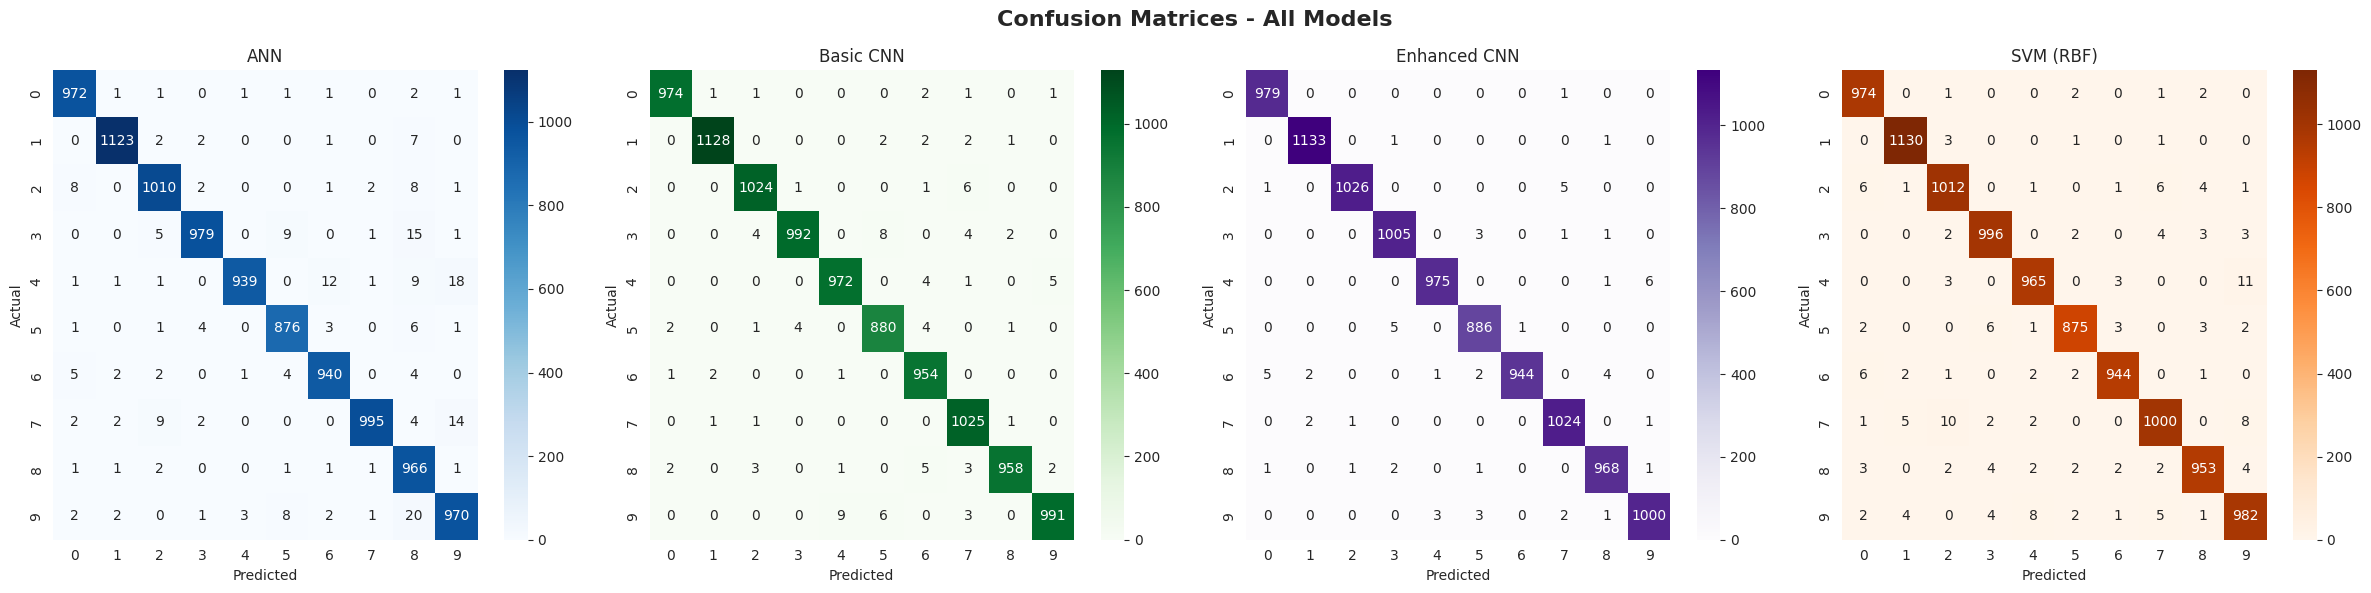

In [24]:
# All confusion matrices side by side
fig, axes = plt.subplots(1, 4, figsize=(24, 6))
fig.suptitle('Confusion Matrices - All Models', fontsize=16, fontweight='bold')
cmaps = ['Blues', 'Greens', 'Purples', 'Oranges']

for i, name in enumerate(names):
    cm = confusion_matrix(y_test, all_results[name]['preds'])
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmaps[i],
                xticklabels=range(10), yticklabels=range(10), ax=axes[i])
    axes[i].set_title(name)
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.tight_layout()
plt.savefig('artifacts/all_confusion_matrices.png')
plt.show()

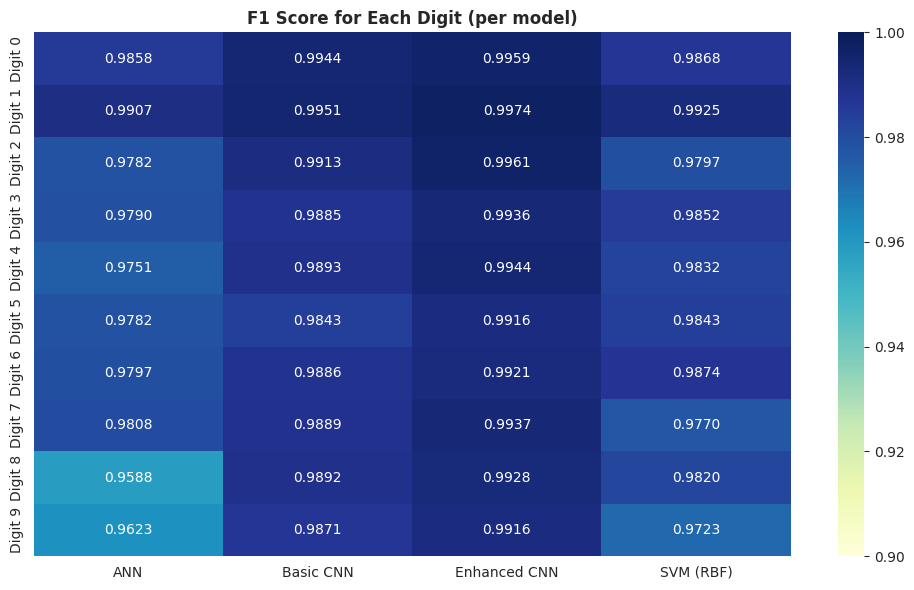

In [25]:
# Per-digit F1 score comparison (which digits are hardest for each model?)
per_digit_f1 = {}
for name in names:
    report = classification_report(y_test, all_results[name]['preds'], output_dict=True)
    per_digit_f1[name] = [report[str(d)]['f1-score'] for d in range(10)]

f1_df = pd.DataFrame(per_digit_f1, index=[f'Digit {d}' for d in range(10)])

plt.figure(figsize=(10, 6))
sns.heatmap(f1_df, annot=True, fmt='.4f', cmap='YlGnBu', vmin=0.9, vmax=1.0)
plt.title('F1 Score for Each Digit (per model)', fontweight='bold')
plt.tight_layout()
plt.savefig('artifacts/per_digit_f1.png')
plt.show()

---
## Section 11: Pick the Best Model

**How we decide:**
1. **Main factor:** Which model has the highest Macro F1 score? (F1 is better than just accuracy because it considers all digits equally)
2. **Also check:** Validation accuracy (to make sure it's not overfitting)
3. **Bonus points:** Faster inference and smaller file size are nice to have

In [26]:
# Find the best and worst models by F1 score
best_name = max(all_results, key=lambda n: all_results[n]['f1_macro'])
worst_name = min(all_results, key=lambda n: all_results[n]['f1_macro'])

best = all_results[best_name]
worst = all_results[worst_name]

print("="*60)
print("  BEST MODEL SELECTION")
print("="*60)
print(f"\n  Winner: {best_name}")

if not np.isnan(best['val_accuracy']):
    print(f"  Validation Accuracy: {best['val_accuracy']*100:.2f}%")
else:
    print(f"  Validation Accuracy: N/A")

print(f"  Test Accuracy:       {best['test_accuracy']*100:.2f}%")
print(f"  Macro F1 Score:      {best['f1_macro']*100:.2f}%")
print(f"  Training Time:       {best['train_time']}s")
print(f"  Inference Speed:     {best['latency_ms']:.4f} ms/image")
print(f"  Model Size:          {best['size_mb']:.2f} MB")
print(f"\n  Why? {best_name} got the highest F1 score, meaning it")
print(f"  classifies all digit classes well overall.")

print(f"\n{'-'*60}")
print(f"  Weakest Model: {worst_name}")
print(f"  Test Accuracy: {worst['test_accuracy']*100:.2f}%")
print(f"  Macro F1:      {worst['f1_macro']*100:.2f}%")

if 'ANN' in worst_name:
    print(f"\n  Why weakest? ANN treats each pixel independently.")
    print(f"  It can't see that nearby pixels form edges and shapes.")
elif 'SVM' in worst_name:
    print(f"\n  Why weakest? SVM works on raw pixel values without")
    print(f"  learning features. It also can't build up layers of")
    print(f"  understanding like neural networks do.")
elif 'Basic' in worst_name:
    print(f"\n  Why weakest? Basic CNN has no regularization to")
    print(f"  prevent overfitting.")
print("="*60)

  BEST MODEL SELECTION

  Winner: Enhanced CNN
  Validation Accuracy: 99.37%
  Test Accuracy:       99.40%
  Macro F1 Score:      99.39%
  Training Time:       137.34s
  Inference Speed:     0.3375 ms/image
  Model Size:          10.07 MB

  Why? Enhanced CNN got the highest F1 score, meaning it
  classifies all digit classes well overall.

------------------------------------------------------------
  Weakest Model: ANN
  Test Accuracy: 97.70%
  Macro F1:      97.69%

  Why weakest? ANN treats each pixel independently.
  It can't see that nearby pixels form edges and shapes.


---
## Section 12: Error Analysis

Let's look at what the best model got **wrong**. This helps us understand its weaknesses.

In [27]:
# Find misclassified images
best_preds = all_results[best_name]['preds']
best_probs = all_results[best_name]['probs']

wrong = np.where(best_preds != y_test)[0]
print(f"{best_name} got {len(wrong)} out of {len(y_test)} images wrong")
print(f"Error rate: {len(wrong)/len(y_test)*100:.2f}%")

Enhanced CNN got 60 out of 10000 images wrong
Error rate: 0.60%


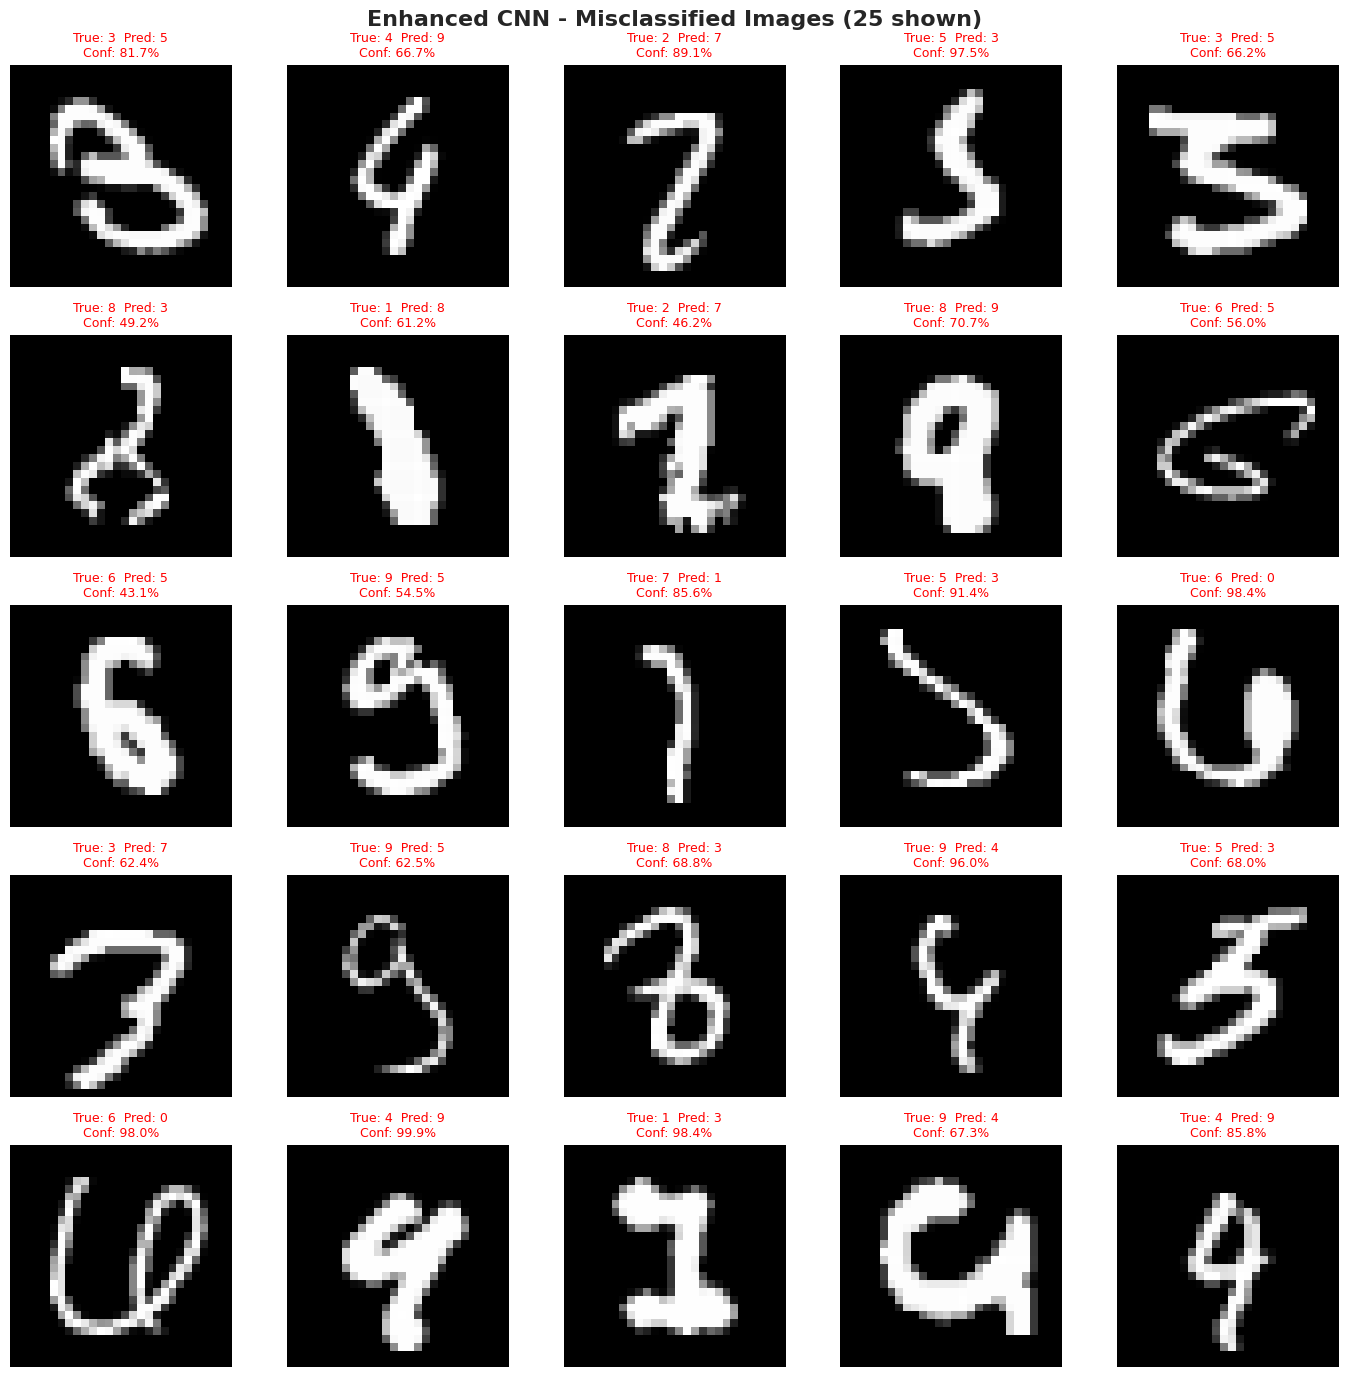

In [28]:
# Show some misclassified images
n_show = min(25, len(wrong))
fig, axes = plt.subplots(5, 5, figsize=(14, 14))
fig.suptitle(f'{best_name} - Misclassified Images ({n_show} shown)', fontsize=16, fontweight='bold')

for i in range(25):
    ax = axes[i//5][i%5]
    if i < n_show:
        idx = wrong[i]
        ax.imshow(x_test[idx], cmap='gray')
        title = f'True: {y_test[idx]}  Pred: {best_preds[idx]}'
        if best_probs is not None:
            conf = best_probs[idx][best_preds[idx]] * 100
            title += f'\nConf: {conf:.1f}%'
        ax.set_title(title, fontsize=9, color='red')
    ax.axis('off')

plt.tight_layout()
plt.savefig('artifacts/misclassified.png')
plt.show()

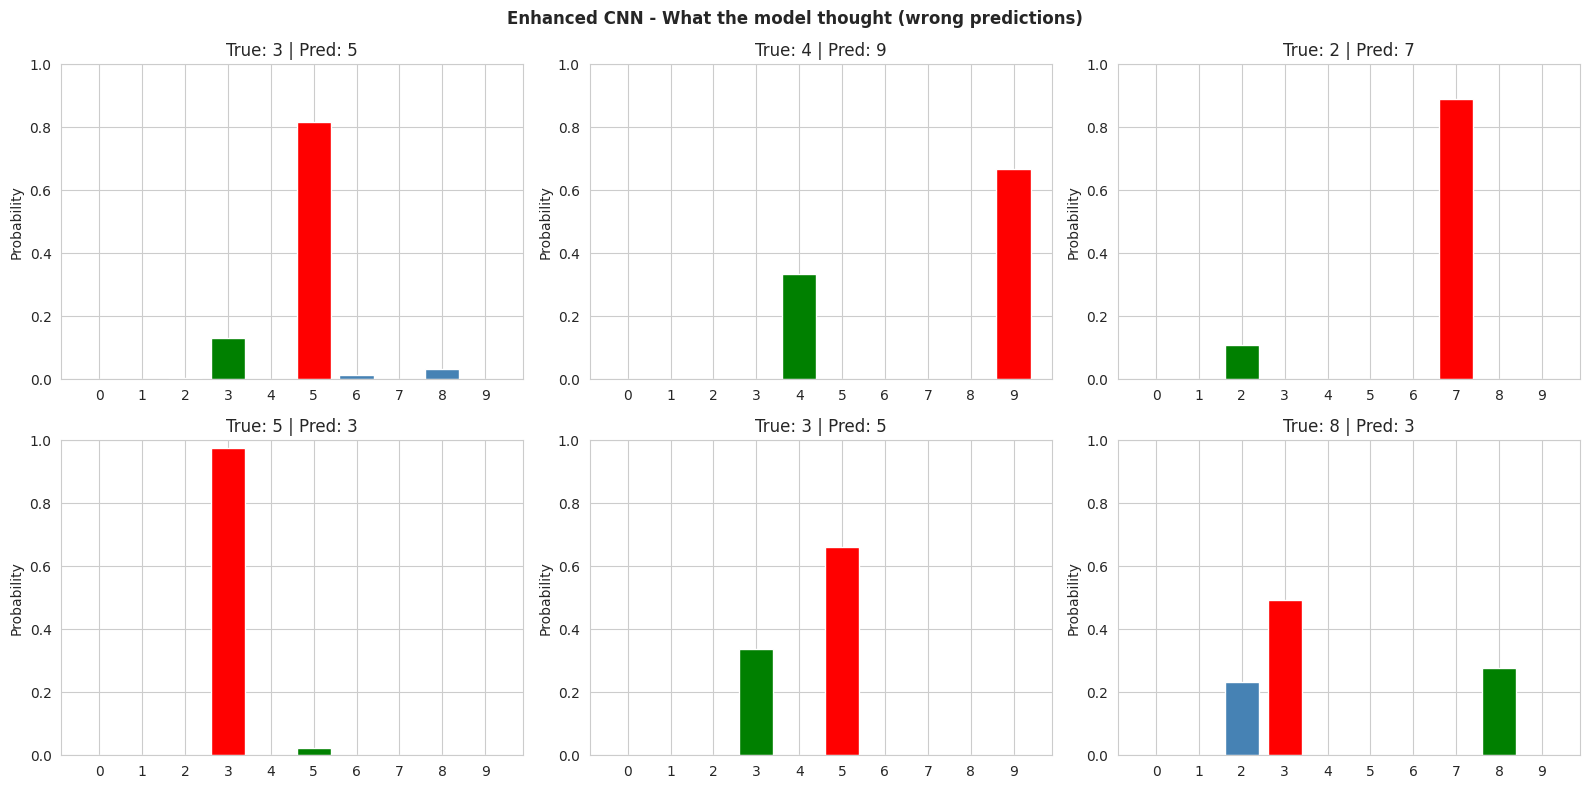

Green bar = correct answer, Red bar = what model predicted


In [29]:
# Show prediction probabilities for some wrong predictions
if best_probs is not None:
    n_prob = min(6, len(wrong))
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    fig.suptitle(f'{best_name} - What the model thought (wrong predictions)', fontweight='bold')

    for i in range(6):
        ax = axes[i//3][i%3]
        if i < n_prob:
            idx = wrong[i]
            probs = best_probs[idx]
            bar_colors = ['red' if d == best_preds[idx] else
                          'green' if d == y_test[idx] else 'steelblue'
                          for d in range(10)]
            ax.bar(range(10), probs, color=bar_colors)
            ax.set_xticks(range(10))
            ax.set_title(f'True: {y_test[idx]} | Pred: {best_preds[idx]}')
            ax.set_ylim(0, 1)
            ax.set_ylabel('Probability')
        else:
            ax.axis('off')

    plt.tight_layout()
    plt.savefig('artifacts/prediction_probs.png')
    plt.show()
    print("Green bar = correct answer, Red bar = what model predicted")
else:
    print("Probability charts not available for SVM.")

In [30]:
# Which digit pairs get confused most often?
cm = confusion_matrix(y_test, best_preds)
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)  # remove correct predictions

print(f"\nMost confused digit pairs ({best_name}):")
print(f"{'True -> Predicted':<20} {'Count'}")
print("-" * 30)

# Find top 5 error pairs
top_errors = np.argsort(cm_errors.ravel())[::-1][:5]
for idx in top_errors:
    true_d = idx // 10
    pred_d = idx % 10
    count = cm_errors[true_d, pred_d]
    if count > 0:
        print(f"  {true_d} -> {pred_d}                {count}")

print("\nWhy these confusions happen:")
print("  - 4 and 9: Both have a vertical line; messy 4s look like 9s")
print("  - 3 and 5: Similar curves, only the top part differs")
print("  - 7 and 2: Some handwriting styles make these look similar")
print("  - 3 and 8: An 8 is basically a 3 with a closed top")

print("\nThings to keep in mind:")
print("  - MNIST images are clean and centered. Real handwriting is messier.")
print("  - A model that works well on MNIST might struggle with")
print("    user-drawn digits that have different stroke styles and sizes.")


Most confused digit pairs (Enhanced CNN):
True -> Predicted    Count
------------------------------
  4 -> 9                6
  2 -> 7                5
  6 -> 0                5
  5 -> 3                5
  6 -> 8                4

Why these confusions happen:
  - 4 and 9: Both have a vertical line; messy 4s look like 9s
  - 3 and 5: Similar curves, only the top part differs
  - 7 and 2: Some handwriting styles make these look similar
  - 3 and 8: An 8 is basically a 3 with a closed top

Things to keep in mind:
  - MNIST images are clean and centered. Real handwriting is messier.
  - A model that works well on MNIST might struggle with
    user-drawn digits that have different stroke styles and sizes.


---
## Section 13: Save the Best Model

We save the winning model along with all the information needed to use it later in a GUI app.

In [31]:
# Copy the best model to a standard filename
best_info = all_results[best_name]

if best_info['type'] == 'keras':
    best_filename = 'best_model.keras'
    if best_name == 'ANN':
        input_shape = [784]
        input_format = 'flattened'
    else:
        input_shape = [28, 28, 1]
        input_format = '2d_grayscale'
else:
    best_filename = 'best_model.joblib'
    input_shape = [784]
    input_format = 'flattened'

best_dest = os.path.join('artifacts', best_filename)
shutil.copy2(best_info['path'], best_dest)
print(f"Best model saved as: {best_dest}")

# Save metadata (info about the model for the GUI)
metadata = {
    'project': 'Handwritten Digit Recognition',
    'best_model_name': best_name,
    'model_type': best_info['type'],
    'model_filename': best_filename,
    'metrics': {
        'test_accuracy': round(best_info['test_accuracy'], 6),
        'macro_f1': round(best_info['f1_macro'], 6),
        'precision': round(best_info['precision'], 6),
        'recall': round(best_info['recall'], 6),
        'model_size_mb': best_info['size_mb'],
    },
    'preprocessing': {
        'normalization': 'divide_by_255',
        'pixel_range': [0.0, 1.0],
        'input_shape': input_shape,
        'input_format': input_format,
        'image_size': [28, 28],
        'color': 'grayscale',
    },
    'output': {
        'num_classes': 10,
        'labels': {str(i): str(i) for i in range(10)}
    },
    'dataset': 'MNIST',
    'seed': SEED
}

with open('artifacts/best_model_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

print("\nMetadata saved! Here's what it contains:")
print(json.dumps(metadata, indent=2))

Best model saved as: artifacts/best_model.keras

Metadata saved! Here's what it contains:
{
  "project": "Handwritten Digit Recognition",
  "best_model_name": "Enhanced CNN",
  "model_type": "keras",
  "model_filename": "best_model.keras",
  "metrics": {
    "test_accuracy": 0.994,
    "macro_f1": 0.993918,
    "precision": 0.993949,
    "recall": 0.993901,
    "model_size_mb": 10.068
  },
  "preprocessing": {
    "normalization": "divide_by_255",
    "pixel_range": [
      0.0,
      1.0
    ],
    "input_shape": [
      28,
      28,
      1
    ],
    "input_format": "2d_grayscale",
    "image_size": [
      28,
      28
    ],
    "color": "grayscale"
  },
  "output": {
    "num_classes": 10,
    "labels": {
      "0": "0",
      "1": "1",
      "2": "2",
      "3": "3",
      "4": "4",
      "5": "5",
      "6": "6",
      "7": "7",
      "8": "8",
      "9": "9"
    }
  },
  "dataset": "MNIST",
  "seed": 42
}


In [32]:
# Quick test: load the saved model and verify it works
print("Verifying saved model...\n")

if best_info['type'] == 'keras':
    test_model = keras.models.load_model(best_dest)
    if 'CNN' in best_name:
        test_input = x_test_cnn[:5]
    else:
        test_input = x_test_flat[:5]
    test_preds = np.argmax(test_model.predict(test_input, verbose=0), axis=1)
else:
    test_model = joblib.load(best_dest)
    test_preds = test_model.predict(x_test_flat[:5])

original = best_preds[:5]
print(f"Loaded model predictions: {test_preds}")
print(f"Original predictions:     {original}")
print(f"Match: {'Yes!' if np.array_equal(test_preds, original) else 'No (something went wrong)'}")

Verifying saved model...

Loaded model predictions: [7 2 1 0 4]
Original predictions:     [7 2 1 0 4]
Match: Yes!


In [33]:
# Package everything into a ZIP file for download
zip_path = 'artifacts/digit_recognition_project.zip'

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    # Add essential files
    for fname in [best_filename, 'best_model_metadata.json', 'comparison_results.csv']:
        fpath = os.path.join('artifacts', fname)
        if os.path.exists(fpath):
            zf.write(fpath, fname)
            print(f"  Added: {fname}")

    # Add all plots
    for fname in os.listdir('artifacts'):
        if fname.endswith('.png'):
            zf.write(os.path.join('artifacts', fname), fname)
            print(f"  Added: {fname}")

zip_size = os.path.getsize(zip_path) / (1024*1024)
print(f"\nZIP created: {zip_path} ({zip_size:.2f} MB)")

# Try to download in Colab
try:
    from google.colab import files
    files.download(zip_path)
    print("Download started!")
except ImportError:
    print("Not in Colab - you can download the ZIP manually from the artifacts folder.")

  Added: best_model.keras
  Added: best_model_metadata.json
  Added: comparison_results.csv
  Added: digit_distribution.png
  Added: ann_curves.png
  Added: basic_cnn_curves.png
  Added: ann_cm.png
  Added: basic_cnn_cm.png
  Added: svm_(rbf)_cm.png
  Added: enhanced_cnn_cm.png
  Added: per_digit_f1.png
  Added: prediction_probs.png
  Added: enhanced_cnn_curves.png
  Added: all_confusion_matrices.png
  Added: comparison_charts.png
  Added: misclassified.png
  Added: sample_digits.png

ZIP created: artifacts/digit_recognition_project.zip (9.85 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started!


---
## Section 14: Conclusion

The conclusion is generated from the actual results (not written beforehand).

In [34]:
# Generate conclusion from actual results
ranked = sorted(all_results.keys(),
                key=lambda n: all_results[n]['test_accuracy'], reverse=True)
best_n = ranked[0]
worst_n = ranked[-1]
gap = (all_results[best_n]['test_accuracy'] - all_results[worst_n]['test_accuracy']) * 100

print("="*60)
print("  CONCLUSION")
print("="*60)

print(f"""
We compared 4 models for handwritten digit recognition on MNIST.

Results ranking (by test accuracy):
""")

for rank, name in enumerate(ranked, 1):
    r = all_results[name]
    print(f"  {rank}. {name:<18} Accuracy: {r['test_accuracy']*100:.2f}%   "
          f"F1: {r['f1_macro']*100:.2f}%   Time: {r['train_time']}s")

print(f"""
Best model: {best_n} ({all_results[best_n]['test_accuracy']*100:.2f}% accuracy)
Worst model: {worst_n} ({all_results[worst_n]['test_accuracy']*100:.2f}% accuracy)
Gap: {gap:.2f} percentage points

Key takeaways:
  - CNNs beat ANN and SVM because they understand image structure
  - BatchNorm and Dropout (Enhanced CNN) help prevent overfitting
  - SVM is competitive but much slower to train on large datasets
  - ANN ignores spatial info, which hurts its performance on images

Limitations:
  - MNIST is clean and centered - real handwriting is messier
  - No data augmentation was used
  - Results may vary slightly on different hardware

Future work:
  - Add data augmentation (rotations, scaling) for better generalization
  - Try learning rate schedules for better training
  - Test on harder datasets like EMNIST
  - Build a GUI app using the saved model (next phase)

The winning model ({best_n}) is saved and ready for GUI integration.
""")
print("="*60)

  CONCLUSION

We compared 4 models for handwritten digit recognition on MNIST.

Results ranking (by test accuracy):

  1. Enhanced CNN       Accuracy: 99.40%   F1: 99.39%   Time: 137.34s
  2. Basic CNN          Accuracy: 98.98%   F1: 98.97%   Time: 49.51s
  3. SVM (RBF)          Accuracy: 98.31%   F1: 98.30%   Time: 158.37s
  4. ANN                Accuracy: 97.70%   F1: 97.69%   Time: 34.66s

Best model: Enhanced CNN (99.40% accuracy)
Worst model: ANN (97.70% accuracy)
Gap: 1.70 percentage points

Key takeaways:
  - CNNs beat ANN and SVM because they understand image structure
  - BatchNorm and Dropout (Enhanced CNN) help prevent overfitting
  - SVM is competitive but much slower to train on large datasets
  - ANN ignores spatial info, which hurts its performance on images

Limitations:
  - MNIST is clean and centered - real handwriting is messier
  - No data augmentation was used
  - Results may vary slightly on different hardware

Future work:
  - Add data augmentation (rotations, sc

---
## Section 15: Viva Questions & Answers

Here are common questions you might be asked during a viva, with simple answers.

---

### Q1: What is the difference between ANN and CNN?
**A:** ANN uses fully connected layers where every neuron connects to every other neuron. It treats the image as a flat list of pixels. CNN uses convolutional filters that slide across the image to detect patterns like edges and shapes. CNN is better for images because it understands spatial relationships.

### Q2: What is convolution?
**A:** Convolution is when a small filter (like 3x3) slides over the image, multiplying and adding values at each position. This creates a "feature map" that highlights certain patterns. For example, one filter might detect horizontal edges, another vertical edges.

### Q3: What is max pooling?
**A:** Max pooling takes a small window (like 2x2) and keeps only the largest value. This shrinks the image and keeps the most important features. It also makes the model less sensitive to small shifts in position.

### Q4: What is ReLU?
**A:** ReLU stands for Rectified Linear Unit. It's a simple function: if the input is positive, output it as is; if negative, output 0. It's used because it's fast and helps the network learn better than older activation functions like sigmoid.

### Q5: Why use softmax in the output layer?
**A:** Softmax converts the network's raw output numbers into probabilities that add up to 1. So instead of random numbers, we get something like "90% chance it's a 7, 8% chance it's a 1, 2% other digits."

### Q6: What loss function did you use and why?
**A:** Sparse categorical cross-entropy. "Categorical" because we have multiple classes (10 digits). "Sparse" because our labels are just numbers (0-9) instead of one-hot vectors. It measures how far the model's predictions are from the true answers.

### Q7: What is the Adam optimizer?
**A:** Adam is a popular optimizer that automatically adjusts the learning rate for each parameter. It combines ideas from two other optimizers (Momentum and RMSProp) and generally works well without much tuning.

### Q8: What are epochs and batch size?
**A:** An epoch is one complete pass through all training data. Batch size is how many images the model looks at before updating its weights. With 54,000 images and batch size 128, the model updates ~422 times per epoch.

### Q9: What is overfitting?
**A:** Overfitting is when the model memorizes the training data instead of learning general patterns. It gets great training accuracy but poor test accuracy. We prevent it with dropout (randomly disabling neurons), batch normalization, and early stopping.

### Q10: Why do we need training, validation, and test sets?
**A:** Training set: for learning. Validation set: for checking progress during training (not used for learning). Test set: for final evaluation only. If we used the test set during training, we'd get an unfairly optimistic score.

### Q11: What are accuracy, precision, recall, and F1-score?
**A:**
- **Accuracy:** What % of predictions are correct overall.
- **Precision:** When the model says it's digit X, how often is it actually X?
- **Recall:** Out of all actual digit X images, how many did the model find?
- **F1-score:** Average of precision and recall (harmonic mean). Useful when you care about both.

### Q12: How do you read a confusion matrix?
**A:** Rows = actual digits, Columns = predicted digits. The diagonal shows correct predictions. Other cells show mistakes. For example, row 4, column 9 shows how many 4s were wrongly predicted as 9.

### Q13: How is SVM different from CNN?
**A:** SVM is a traditional ML algorithm that draws decision boundaries between classes. It works on flat pixel vectors and doesn't learn features. CNN learns features automatically through convolutional layers. CNNs are generally better for images.

### Q14: How did you pick the best model?
**A:** We compared all models on the test set using Macro F1 score as the main metric (it treats all digits equally). We also checked validation accuracy to make sure the model isn't overfitting. The model with the highest F1 score won.

### Q15: What are the limitations of this project?
**A:** MNIST is clean and simple - real handwriting is messier. No data augmentation was used. SVM hyperparameters weren't fully optimized. Results may vary slightly between runs due to GPU randomness.

### Q16: What is Batch Normalization?
**A:** It normalizes (rescales) the values flowing through the network at each layer. This makes training more stable and allows higher learning rates. It also acts as a mild form of regularization.

### Q17: Why didn't you use the test set during training?
**A:** That would be "data leakage." The model would learn from the test data, and our final accuracy score would be misleadingly high. The test set must stay completely separate to give an honest measure of performance.

### Q18: How would you use this model in a GUI?
**A:** Load the saved model and metadata JSON in a separate app (like Tkinter). The GUI lets the user draw a digit, then: resize it to 28x28, convert to grayscale, normalize pixels to 0-1, reshape to the expected input shape, and feed it to the model for prediction. The JSON file tells us exactly how to preprocess.

---

## Done!

Everything is saved in the `artifacts/` folder:
- Best model file
- Metadata JSON (preprocessing info for the GUI)
- Comparison CSV
- All charts and plots
- ZIP file containing everything

**Next step:** Build a GUI application using the saved model.

---